In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import preprocessing as pp, feature_engineering as fe, pipeline as P
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
def show(name, w=800): display(Image(filename=str(FIG / name), width=w))

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 05 Exploratory data analysis
Figures are produced by `P.stage_eda`; each cell notes what the figure shows.

In [2]:
m = pd.read_csv(PROC/'irf_facilities_merged.csv', dtype={CCN:str}, parse_dates=['Certification Date'])
df = pd.read_csv(PROC/'facility_quality_index.csv', dtype={CCN:str})
Pm = fe.direction_adjusted_percentiles(m[list(INDEX_MEASURES)])
desc, own, reg, miss = P.stage_eda(m, df, Pm)
desc

/home/claude/irf_project/notebooks/../src/pipeline.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=t, x="performance_category", y=c, order=CLASS_ORDER, palette=PAL, ax=a); a.set(title=SHORT[c][:42], xlabel="", ylabel="")
/home/claude/irf_project/notebooks/../src/pipeline.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=t, x="performance_category", y=c, order=CLASS_ORDER, palette=PAL, ax=a); a.set(title=SHORT[c][:42], xlabel="", ylabel="")
/home/claude/irf_project/notebooks/../src/pipeline.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same e

/home/claude/irf_project/notebooks/../src/pipeline.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=t, x="performance_category", y=c, order=CLASS_ORDER, palette=PAL, ax=a); a.set(title=SHORT[c][:42], xlabel="", ylabel="")


,count,mean,std,min,25%,50%,75%,max
C. difficile infection SIR,977.0,0.335,0.434,0.00,0.000,0.223,0.517,3.382
Falls with major injury (%),1135.0,0.139,0.215,0.00,0.000,0.000,0.225,2.440
"New/worsened pressure ulcers, risk-adj. (%)",1135.0,0.897,1.012,0.00,0.210,0.560,1.270,9.460
Preventable 30-day post-discharge readmission (RSRR),1126.0,9.469,0.874,7.04,8.890,9.400,10.010,12.720
Preventable within-stay readmission (RSRR),1126.0,4.783,0.785,2.90,4.230,4.680,5.200,8.080
"Discharge to community, risk-std. (%)",1126.0,67.286,5.179,37.40,64.602,67.790,70.558,82.360
Discharge function score met/exceeded (%),1134.0,64.191,18.980,0.00,51.950,65.970,80.462,96.300
Drug regimen review with follow-up (%),1135.0,97.435,9.034,0.00,98.330,99.470,100.000,100.000
Med list to next care setting (%),1126.0,96.702,10.689,1.17,98.708,99.830,100.000,100.000
Med list to patient/caregiver (%),1027.0,98.278,5.129,0.00,98.000,100.000,100.000,100.000


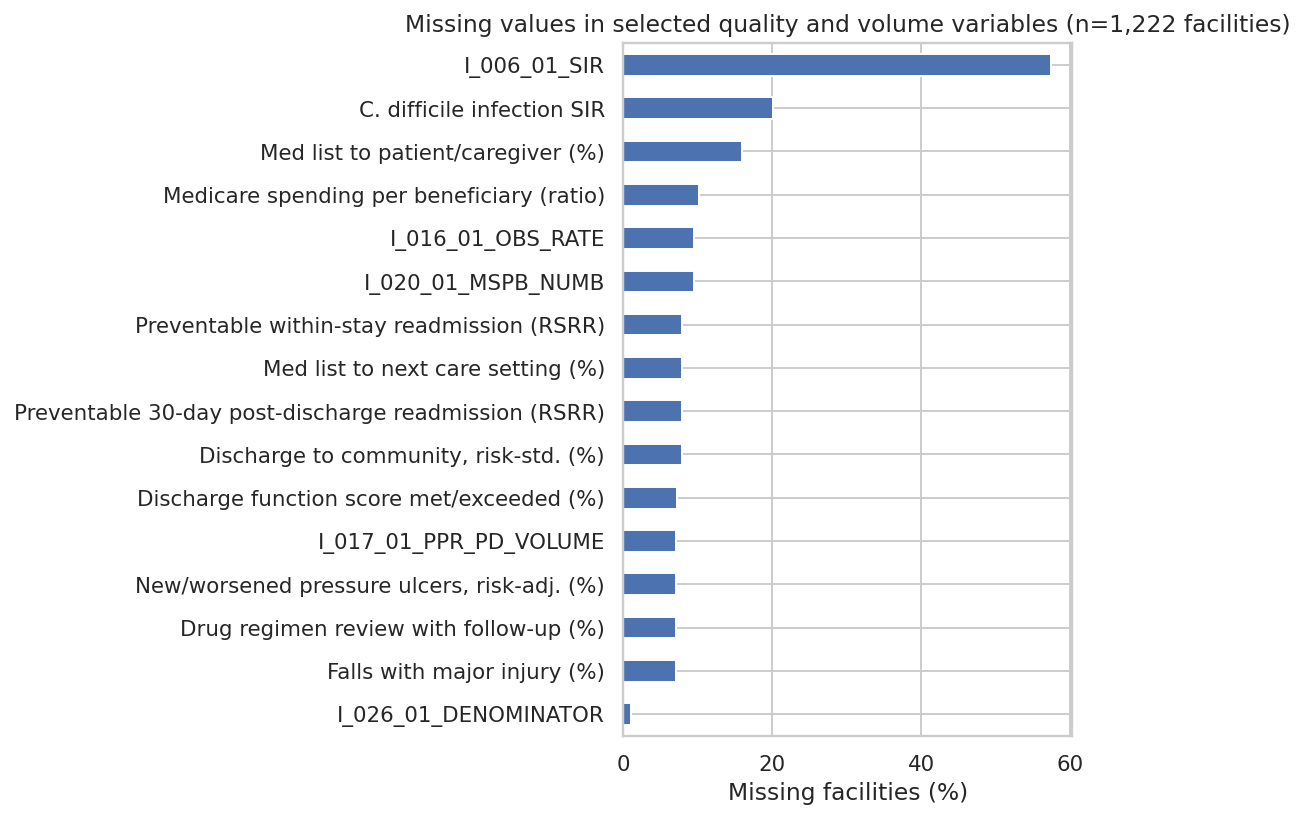

I_026_01_DENOMINATOR       1.1
I_013_01_OBS_RATE          7.1
I_021_01_OBS_RATE          7.1
I_022_01_ADJ_RATE          7.1
I_017_01_PPR_PD_VOLUME     7.1
I_026_01_OBS_RATE          7.2
I_019_02_DTC_RS_RATE       7.9
I_017_01_PPR_PD_RSRR       7.9
I_024_01_OBS_RATE          7.9
I_018_01_PPR_WI_RSRR       7.9
I_020_01_MSPB_NUMB         9.5
I_016_01_OBS_RATE          9.5
I_020_01_MSPB_SCORE       10.1
I_025_02_OBS_RATE         16.0
I_015_01_SIR              20.0
I_006_01_SIR              57.4
dtype: float64

In [3]:
show('fig01_missingness.png', 650); miss.round(1)

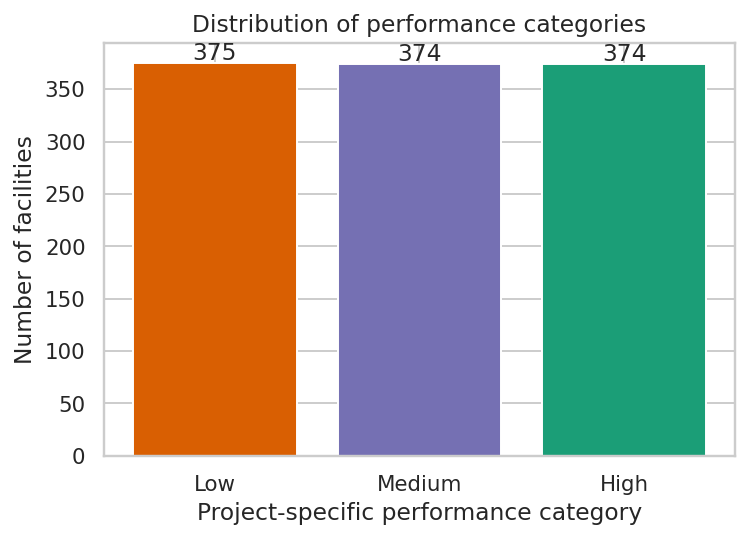

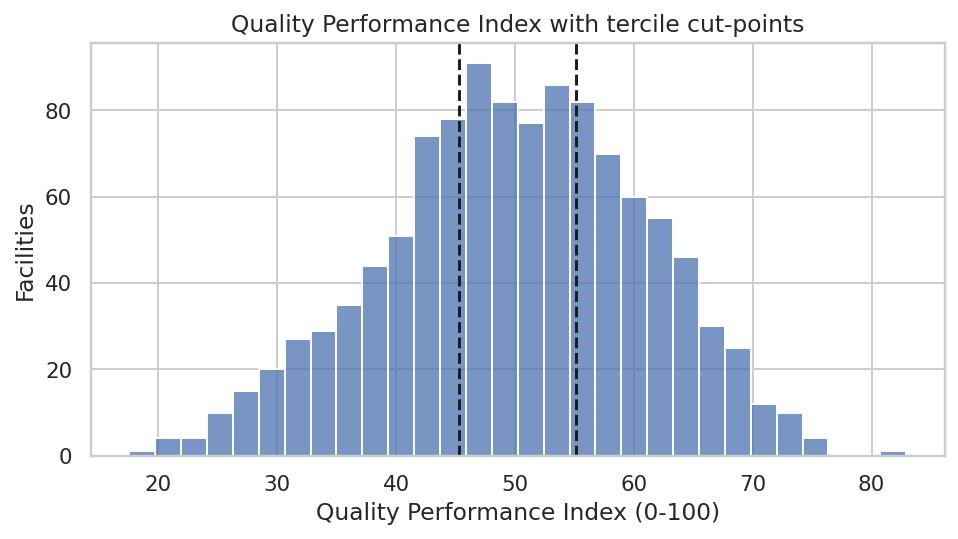

In [4]:
show('fig02_category_distribution.png', 450); show('fig06_index_distribution.png', 550)

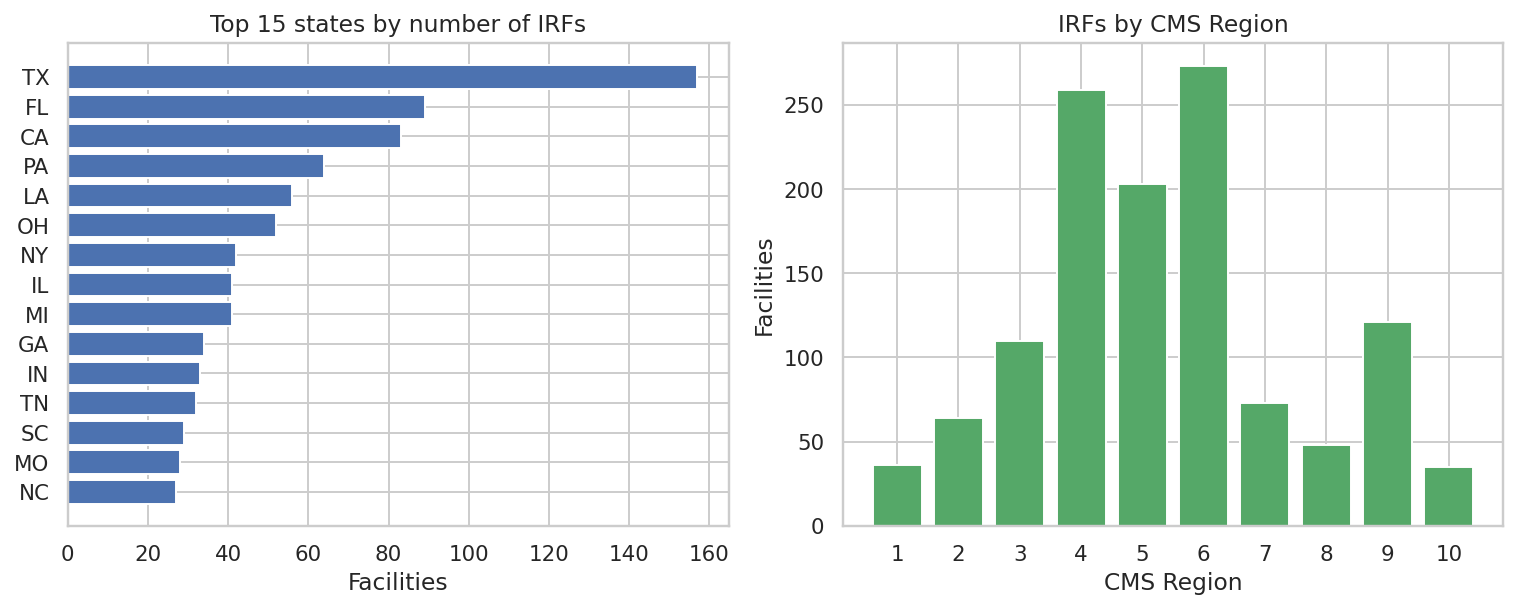

,facilities,median,mean
Ownership Type,,,
Non-profit,569,52.15,51.57
For profit,545,48.44,48.13
Government,100,50.51,51.29
Physician,8,44.12,43.69


In [5]:
show('fig03_geography.png'); own

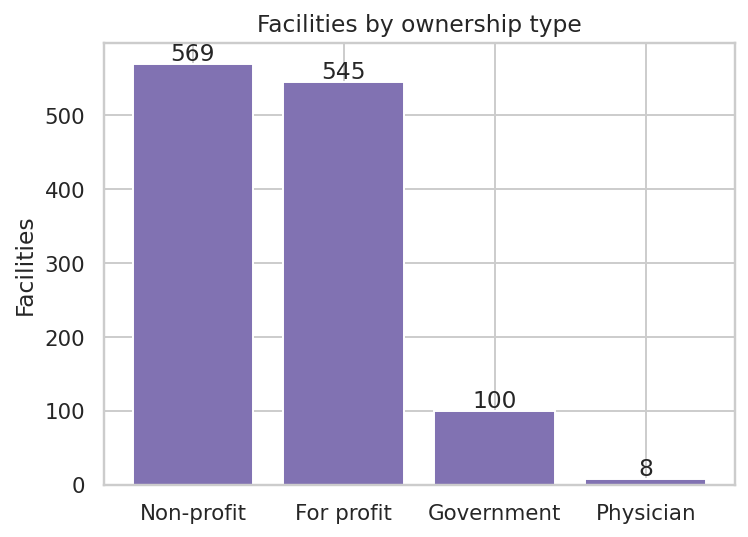

,facilities,median,mean
CMS Region,,,
1,36,48.97,48.97
2,64,50.24,49.06
3,110,52.91,51.72
4,259,51.78,50.79
5,203,49.57,49.70
6,273,47.09,46.53
7,73,52.31,51.91
8,48,56.48,54.36
9,121,49.86,50.36


In [6]:
show('fig04_ownership.png', 450); reg

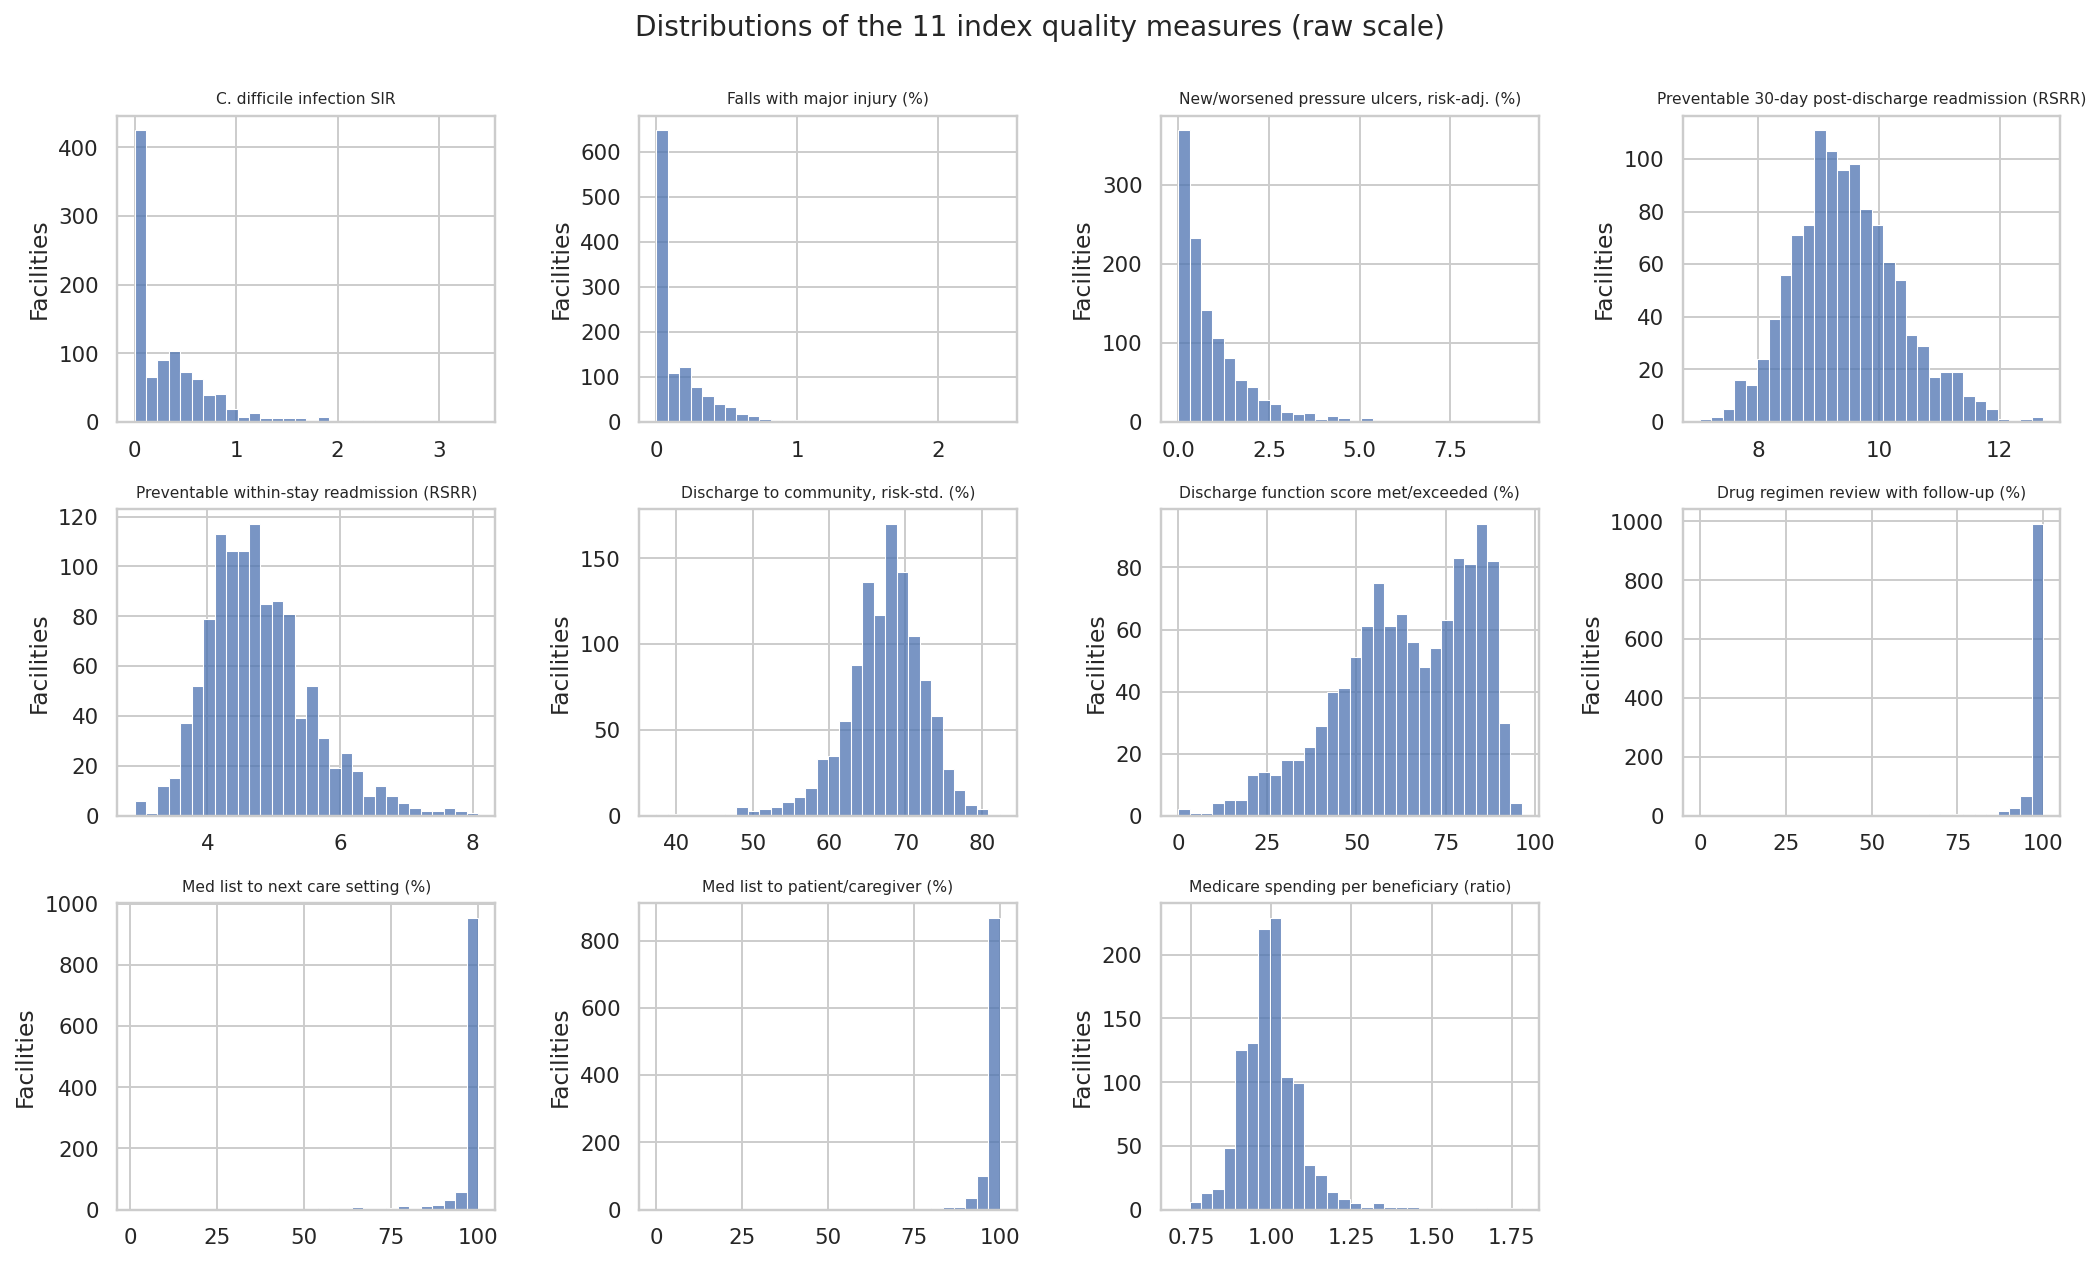

In [7]:
show('fig05_measure_distributions.png')

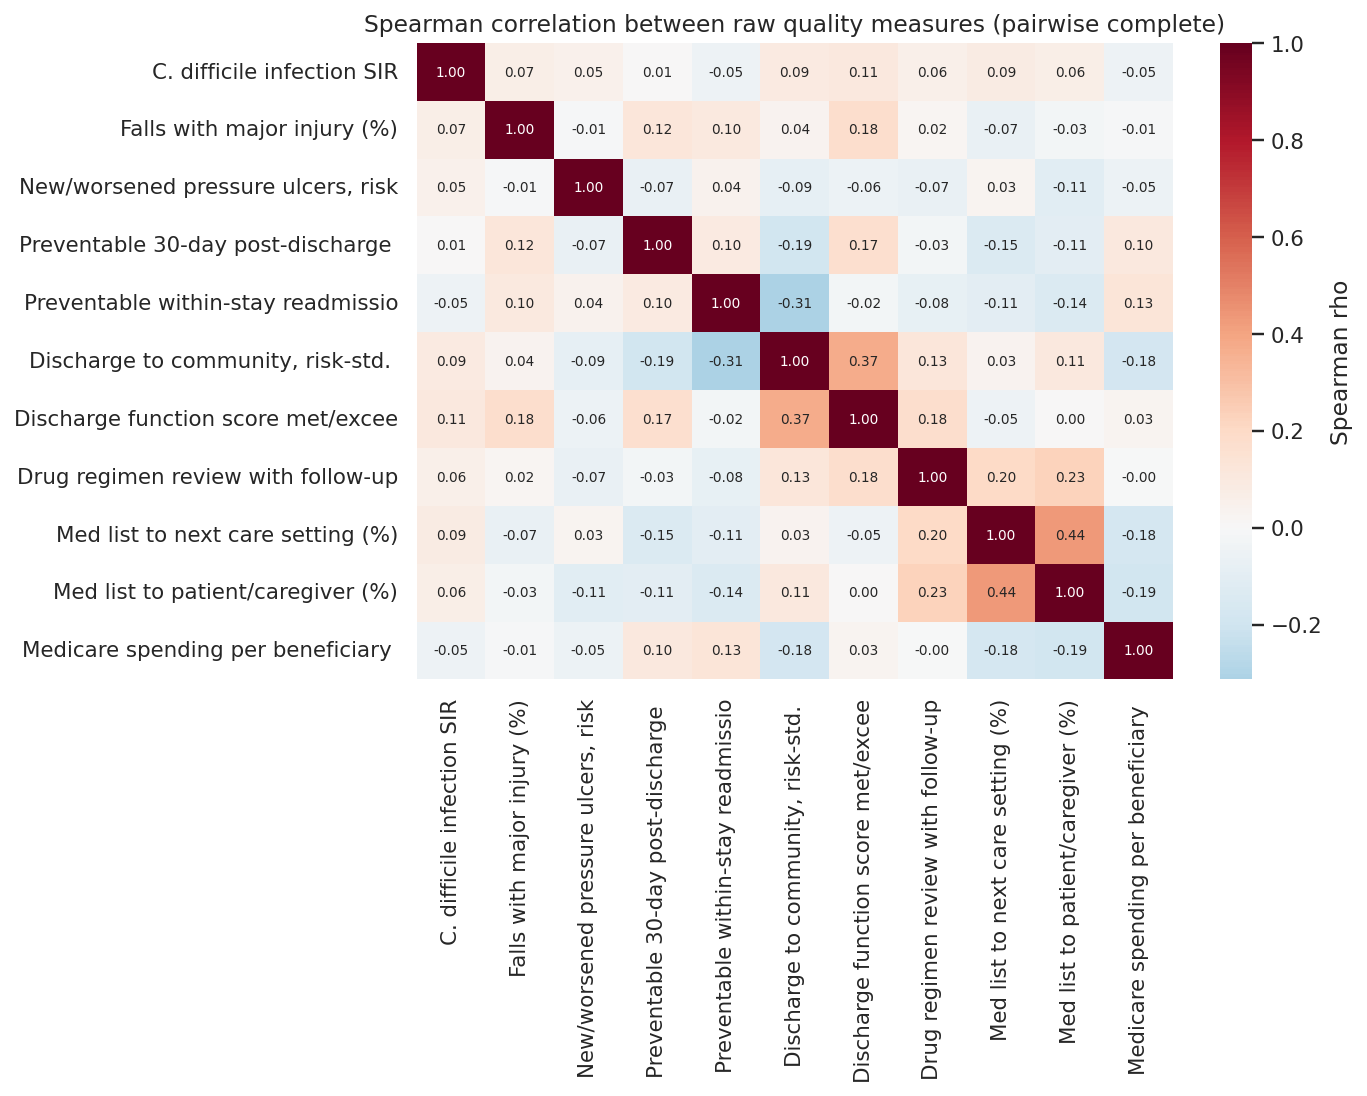

In [8]:
show('fig07_correlation_heatmap.png', 750)

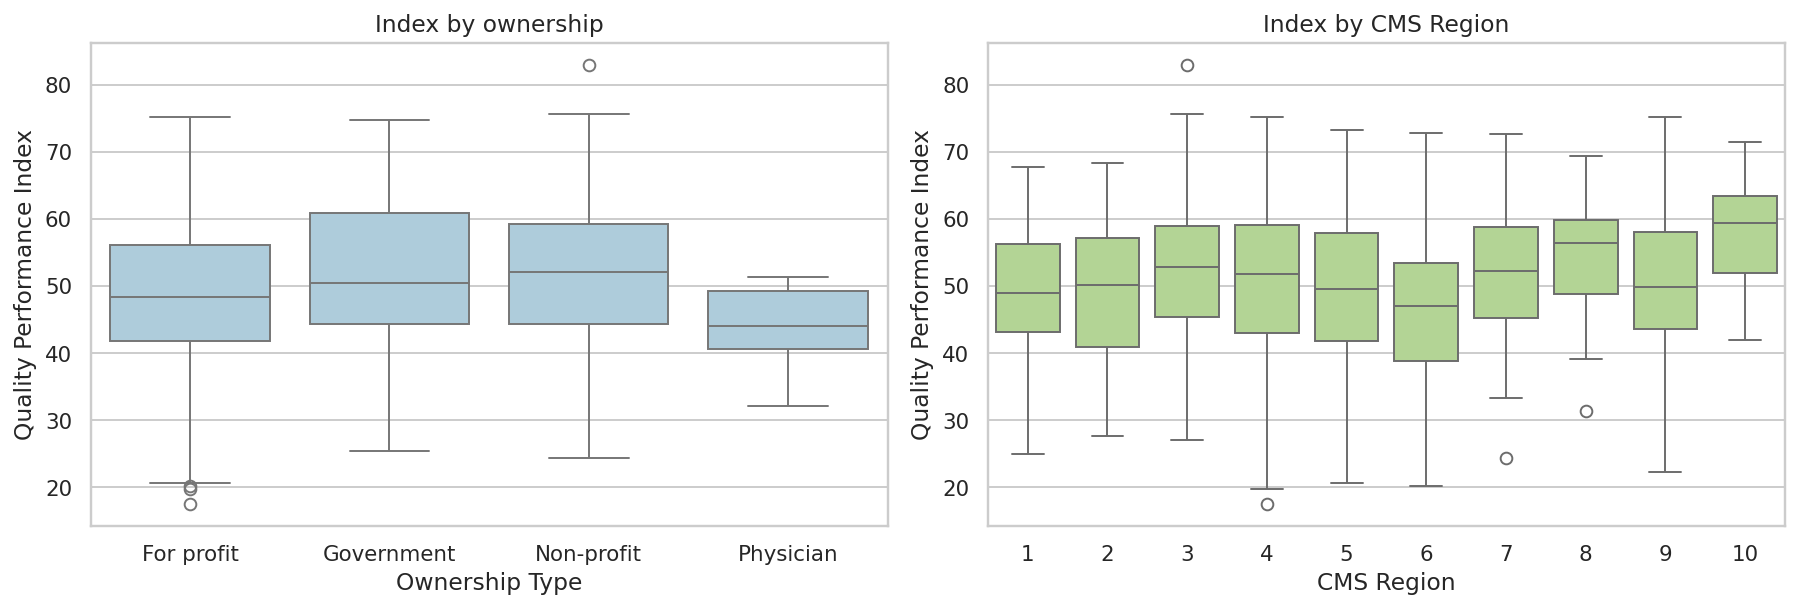

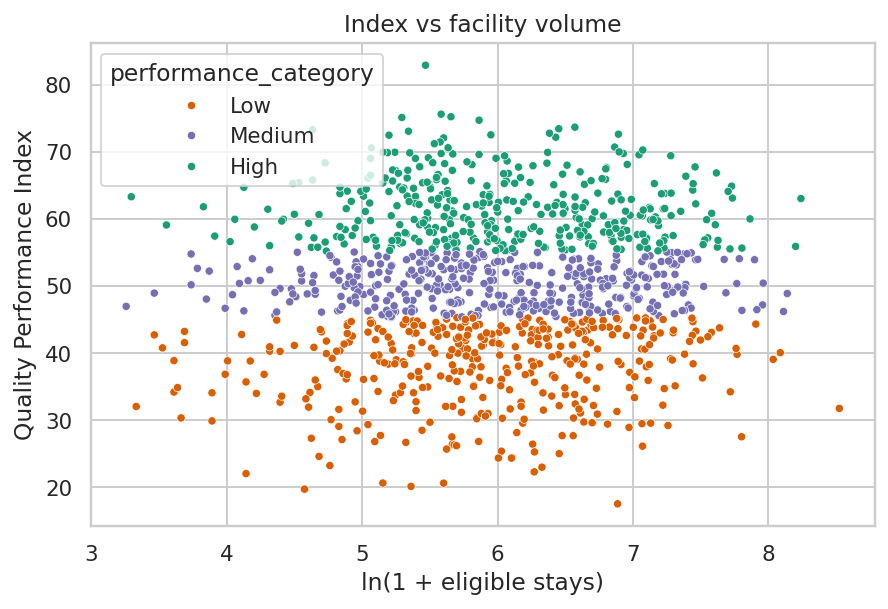

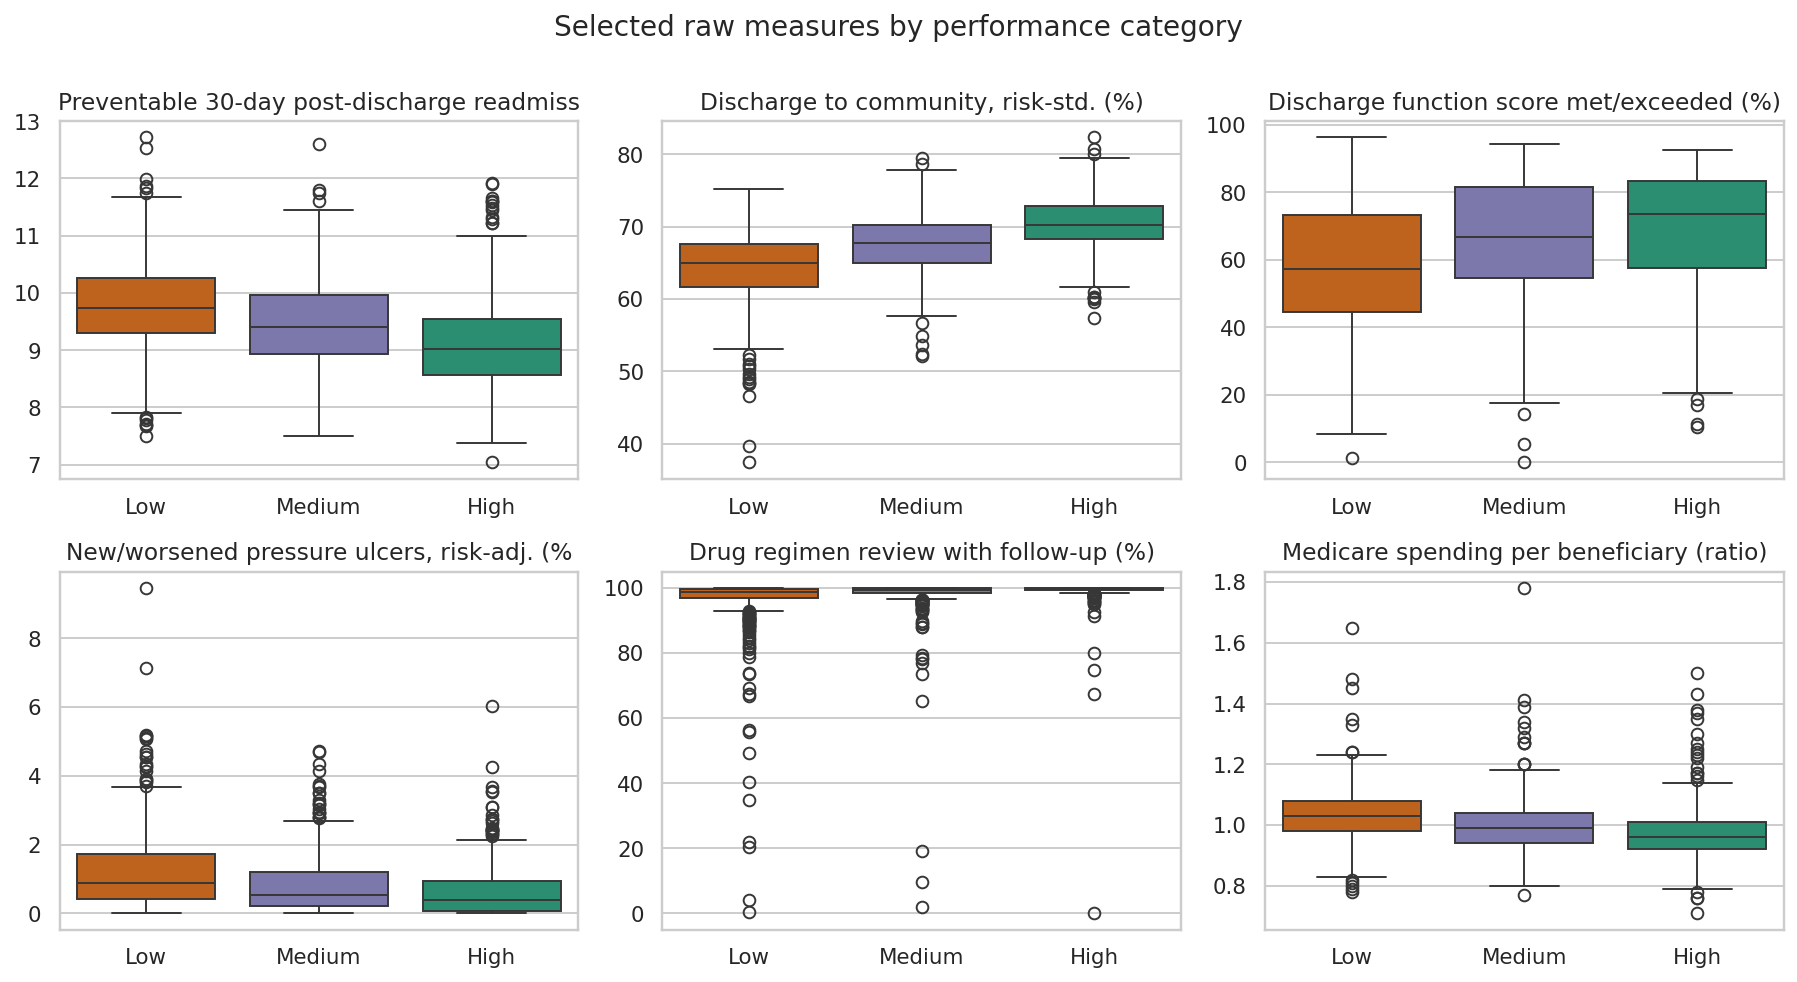

In [9]:
show('fig08_boxplots_ownership_region.png'); show('fig09_index_vs_volume.png', 550); show('fig10_measures_by_category.png')

Interpretations for the report are written from the *printed numbers* (see `outputs/tables`) - none are hard-coded.